# 活动空间变化模式的聚类分析

In [1]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import geopandas as gpd
import contextily as ctx
from shapely.geometry import Point, Polygon
from shapely import wkt
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.cluster import KMeans
from tslearn.metrics import dtw, cdist_dtw
from sklearn.neighbors import KernelDensity
from sklearn_extra.cluster import KMedoids
from IPython.display import HTML, Image

In [2]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.font_manager import FontProperties
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.transforms as mtransforms
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import matplotlib.image as mpimg

## 0. data load

In [2]:
df = pd.read_csv('../data/act_space_travel_features.csv')
df.head()

,pid,area0,area1,area2,area3,cluster0,cluster1,cluster2,cluster3,home_density_0,...,avg_daily_slow_freq2,avg_daily_slow_freq3,avg_daily_tube_dist0,avg_daily_tube_dist1,avg_daily_tube_dist2,avg_daily_tube_dist3,avg_daily_tube_freq0,avg_daily_tube_freq1,avg_daily_tube_freq2,avg_daily_tube_freq3
0,270.0,3.147451,3.308764,3.235937,3.434450,1,1,1,1,14.529677,...,0.194327,0.197484,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
1,2753.0,3.404565,3.226078,3.234076,3.220988,1,1,1,1,43.323924,...,0.158750,0.162321,6516.841111,6516.841111,3817.016667,3817.016667,0.302222,0.302222,0.35000,0.350000
2,4100.0,4.208079,4.887184,5.050174,4.030251,2,2,2,2,32.723039,...,0.176699,0.215924,10402.511857,6796.715000,6265.231250,7152.244932,0.822429,0.642500,0.76750,1.058679
3,4658.0,3.530046,3.069087,3.043223,3.064848,2,1,1,1,26.280335,...,0.148523,0.155152,7890.081607,12649.038810,8455.105000,7646.896667,0.637765,0.950455,0.50825,0.443111
4,4942.0,3.458569,5.794304,3.526932,3.464373,2,2,1,2,21.517534,...,0.281620,0.225618,0.000000,0.000000,433.860000,433.860000,0.000000,0.000000,0.14000,0.140000


## 1. Cluster聚类

In [3]:
cluster = df[['cluster0','cluster1','cluster2','cluster3']].drop_duplicates().values
print(cluster)
print(cluster.shape)

[[1 1 1 1]
 [2 2 2 2]
 [2 1 1 1]
 ...
 [5 4 3 1]
 [3 3 5 3]
 [1 4 3 1]]
(280, 4)


In [4]:
# 使用DTW距离的K-Medoids聚类
distance_matrix = cdist_dtw(cluster)  # 计算DTW距离矩阵

/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/sklearn_extra/cluster/_k_medoids.py:329: UserWarning: Cluster 8 is empty! self.labels_[self.medoid_indices_[8]] may not be labeled with its corresponding cluster (8).
  warnings.warn(
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/sklearn_extra/cluster/_k_medoids.py:329: UserWarning: Cluster 8 is empty! self.labels_[self.medoid_indices_[8]] may not be labeled with its corresponding cluster (8).
  warnings.warn(


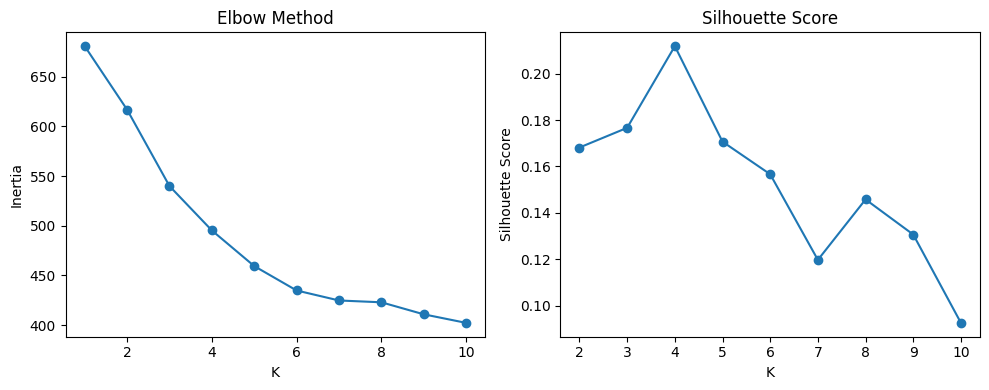

In [5]:
# 遍历K值计算损失
k_range = range(1, 11)
inertias, silhouette_scores = [], []

for k in k_range:
    kmedoids = KMedoids(n_clusters=k, metric="precomputed", random_state=0)
    labels = kmedoids.fit_predict(distance_matrix)
    inertias.append(kmedoids.inertia_)
    
    if k > 1:
        score = silhouette_score(distance_matrix, labels, metric="precomputed")
        silhouette_scores.append(score)

# 绘制肘部图
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(k_range, inertias, marker='o')
plt.xlabel('K')
plt.ylabel('Inertia')
plt.title('Elbow Method')

# 绘制轮廓系数
plt.subplot(1, 2, 2)
plt.plot(k_range[1:], silhouette_scores, marker='o')
plt.xlabel('K')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()

选择聚类簇数为4进行聚类

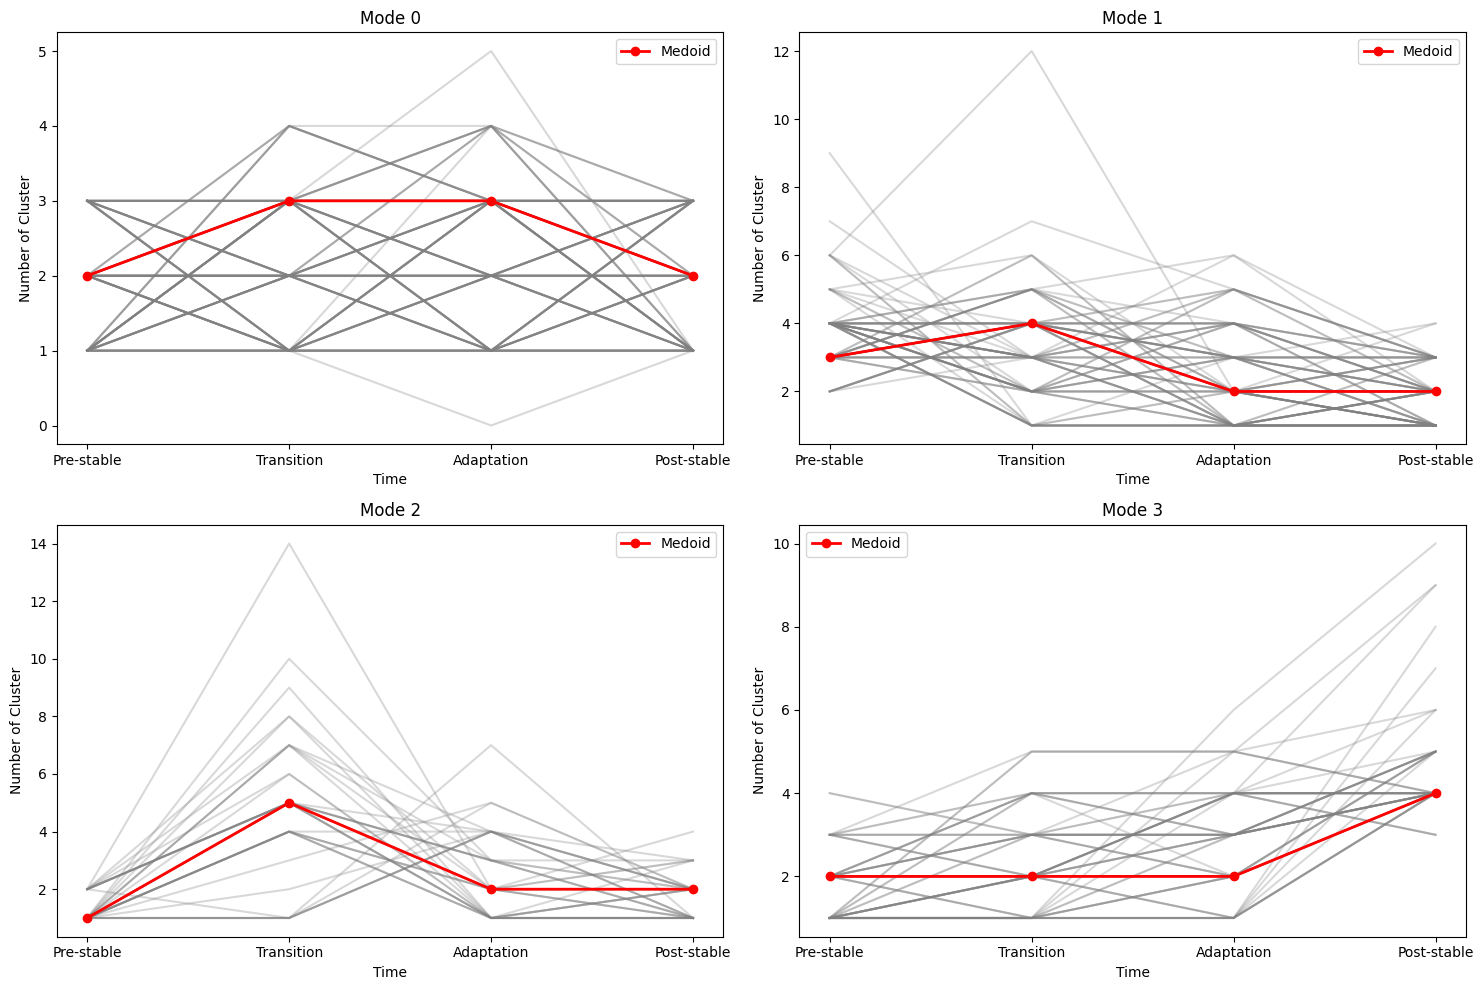

簇 0 的样本数量: 99
簇 1 的样本数量: 86
簇 2 的样本数量: 39
簇 3 的样本数量: 56


In [6]:
# 使用K=4进行聚类
k = 4
kmedoids = KMedoids(n_clusters=k, metric="precomputed", random_state=0)
labels = kmedoids.fit_predict(distance_matrix)

# 绘制每个簇的时间序列模式
plt.figure(figsize=(15, 10))
for i in range(k):
    plt.subplot(2, 2, i+1)
    cluster_data = cluster[labels == i].T
    
    # 绘制所有时间序列
    for j in range(cluster_data.shape[1]):
        plt.plot(cluster_data[:, j], 'gray', alpha=0.3)
    
    # 绘制中心点时间序列
    medoid_idx = kmedoids.medoid_indices_[i]
    plt.plot(cluster[medoid_idx], 'r', linewidth=2, marker='o', label='Medoid')
    
    plt.title(f'Mode {i}')
    # 设置x轴刻度
    plt.xticks([0, 1, 2, 3], ['Pre-stable', 'Transition', 'Adaptation', 'Post-stable'])
    plt.xlabel('Time')
    plt.ylabel('Number of Cluster')
    plt.legend()

plt.tight_layout()
plt.show()

# 打印每个簇的大小
for i in range(k):
    print(f"簇 {i} 的样本数量: {sum(labels==i)}")


In [7]:
# 创建一个字典来存储聚类结果
cluster_dict = {}
unique_patterns = df[['cluster0','cluster1','cluster2','cluster3']].drop_duplicates().values
for i, pattern in enumerate(unique_patterns):
    cluster_dict[tuple(pattern)] = labels[i]

# 将聚类标签添加到原始数据框中
df['label'] = df.apply(lambda row: cluster_dict[tuple(row[['cluster0','cluster1','cluster2','cluster3']])], axis=1)

# 显示前几行结果以验证
print(df[['pid', 'cluster0', 'cluster1', 'cluster2', 'cluster3', 'label']].head())
print(df['label'].value_counts())

      pid  cluster0  cluster1  cluster2  cluster3  label
0   270.0         1         1         1         1      0
1  2753.0         1         1         1         1      0
2  4100.0         2         2         2         2      0
3  4658.0         2         1         1         1      0
4  4942.0         2         2         1         2      0
label
0    84324
1      278
3      141
2      117
Name: count, dtype: int64


In [7]:
mean_analyze_cols = ['home_density_0', 'home_landusemix_0', 'home_road_density_0', 'home_openratio_wide_0', 'home_subway_0', 'home_bus_0', 'home_center_0', 
                 'work_density_0', 'work_landusemix_0', 'work_road_density_0', 'work_openratio_wide_0', 'work_subway_0', 'work_bus_0', 'work_center_0', 
                 'commute_distance_0', 'home_density_1', 'home_landusemix_1', 'home_road_density_1', 'home_openratio_wide_1', 'home_subway_1', 'home_bus_1', 
                 'home_center_1', 'work_density_1', 'work_landusemix_1', 'work_road_density_1', 'work_openratio_wide_1', 'work_subway_1', 'work_bus_1', 
                 'work_center_1', 'commute_distance_1', 'edu', 'married', 'home_density_change', 'home_landusemix_change',
                 'home_road_density_change', 'home_openratio_wide_change', 'home_subway_change', 'home_bus_change', 'home_center_change', 'work_density_change', 
                 'work_landusemix_change', 'work_road_density_change', 'work_openratio_wide_change', 'work_subway_change', 'work_bus_change', 'work_center_change']

count_analyze_cols = ['gender', 'age', 'income', 'state']

In [8]:
# 创建mean_analyze_cols的统计DataFrame
mean_stats = []
# 先计算整体平均值
mean_stats.append(df[mean_analyze_cols].mean())
# 再计算各簇平均值
for label in sorted(df['label'].unique()):
    mean_stats.append(df[df['label']==label][mean_analyze_cols].mean())

mean_stats_df = pd.DataFrame(mean_stats, 
                           index=['All'] + [f'Mode{i}' for i in sorted(df['label'].unique())],
                           columns=mean_analyze_cols)

# 创建count_analyze_cols的统计DataFrame
# 创建一个空的DataFrame来存储所有结果
count_stats_df = pd.DataFrame(index=['All'] + [f'Mode{i}' for i in sorted(df['label'].unique())])

# 对每个离散变量
for col in count_analyze_cols:
    # 获取该变量的所有可能取值
    unique_values = sorted(df[col].unique())
    
    # 对每个取值计算占比
    for val in unique_values:
        col_name = f'{col}{val}'
        
        # 计算整体占比
        all_ratio = len(df[df[col]==val]) / len(df)
        count_stats_df.loc['All', col_name] = all_ratio
        
        # 计算各簇占比
        for label in sorted(df['label'].unique()):
            cluster_df = df[df['label']==label]
            ratio = len(cluster_df[cluster_df[col]==val]) / len(cluster_df)
            count_stats_df.loc[f'Mode{label}', col_name] = ratio


In [17]:
mean_stats_df.to_csv('results/cluster_mean_stats.csv')

In [18]:
count_stats_df.to_csv('results/cluster_count_stats.csv')

## 2. Area聚类

In [8]:
# 计算area变化百分比
area_cols = ['area0', 'area1', 'area2', 'area3']
area_change_cols = []
area_df = df[area_cols+['pid']].copy()  # 使用copy()避免SettingWithCopyWarning

for i in range(1, len(area_cols)):
    prev_col = area_cols[i-1]
    curr_col = area_cols[i]
    change_col = f'area{i-1}_to_{i}_change (%)'
    area_df.loc[:, change_col] = (area_df[curr_col] - area_df[prev_col]) / area_df[prev_col] * 100
    area_change_cols.append(change_col)

# 显示前几行结果
area_df.head()


,area0,area1,area2,area3,pid,area0_to_1_change (%),area1_to_2_change (%),area2_to_3_change (%)
0,3.147451,3.308764,3.235937,3.434450,270.0,5.125191,-2.201035,6.134635
1,3.404565,3.226078,3.234076,3.220988,2753.0,-5.242584,0.247909,-0.404684
2,4.208079,4.887184,5.050174,4.030251,4100.0,16.138118,3.335053,-20.195785
3,3.530046,3.069087,3.043223,3.064848,4658.0,-13.058173,-0.842700,0.710578
4,3.458569,5.794304,3.526932,3.464373,4942.0,67.534744,-39.131046,-1.773751


In [9]:
# 根据变化百分比创建分类变量
for col in area_change_cols:
    new_col = col.replace('change (%)', 'category')
    area_df[new_col] = 0  # 默认为0(无显著变化)
    area_df.loc[area_df[col] > 10, new_col] = 1  # 显著增长
    area_df.loc[area_df[col] < -10, new_col] = -1  # 显著下降

# 显示前几行结果
area_df.head()

,area0,area1,area2,area3,pid,area0_to_1_change (%),area1_to_2_change (%),area2_to_3_change (%),area0_to_1_category,area1_to_2_category,area2_to_3_category
0,3.147451,3.308764,3.235937,3.434450,270.0,5.125191,-2.201035,6.134635,0,0,0
1,3.404565,3.226078,3.234076,3.220988,2753.0,-5.242584,0.247909,-0.404684,0,0,0
2,4.208079,4.887184,5.050174,4.030251,4100.0,16.138118,3.335053,-20.195785,1,0,-1
3,3.530046,3.069087,3.043223,3.064848,4658.0,-13.058173,-0.842700,0.710578,-1,0,0
4,3.458569,5.794304,3.526932,3.464373,4942.0,67.534744,-39.131046,-1.773751,1,-1,0


In [10]:
# 提取分类变量
area_categories = area_df[['area0_to_1_category', 'area1_to_2_category', 'area2_to_3_category']].drop_duplicates().values

# 计算DTW距离矩阵
distance_matrix = cdist_dtw(area_categories)

# 使用K-medoids聚类
n_clusters = 4  # 可以根据需要调整聚类数
kmedoids = KMedoids(n_clusters=n_clusters, metric='precomputed', random_state=42)
area_labels = kmedoids.fit_predict(distance_matrix)

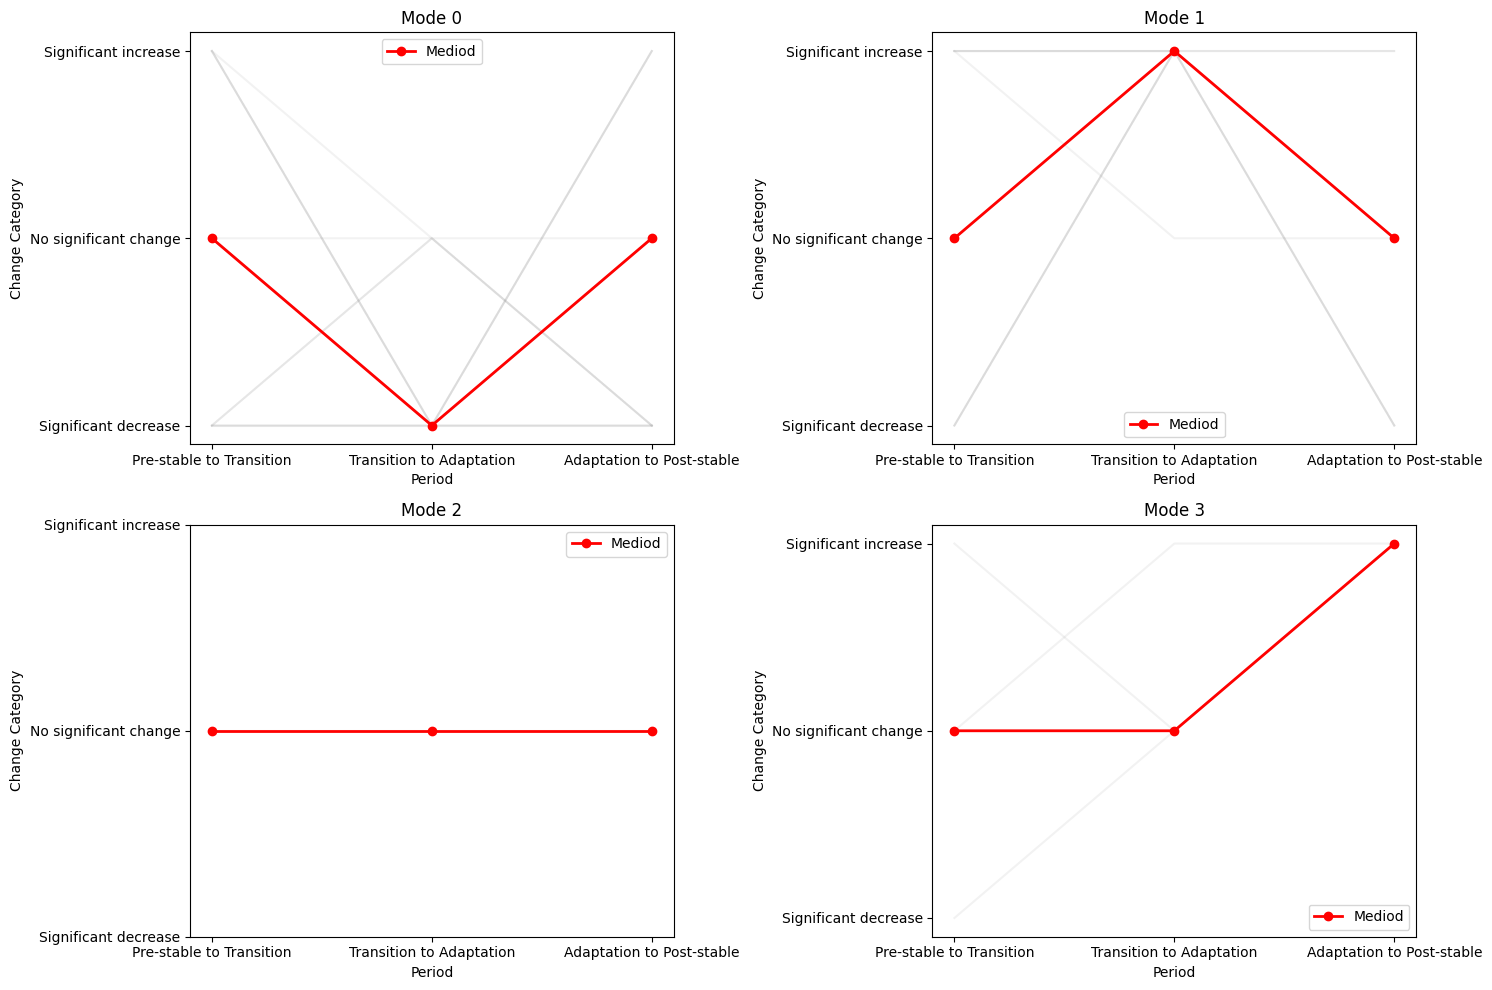

In [11]:
# 创建一个图形
plt.figure(figsize=(15, 10))

# 为每个聚类创建一个子图
for i in range(n_clusters):
    plt.subplot(2, 2, i+1)
    
    # 获取当前聚类的所有序列
    cluster_sequences = area_categories[area_labels == i]
    
    # 获取聚类中心点序列
    center_sequence = area_categories[kmedoids.medoid_indices_[i]]
    
    # 绘制所有序列（透明度较低）
    for seq in cluster_sequences:
        plt.plot(range(3), seq, color='gray', alpha=0.1)
    
    # 绘制聚类中心序列（加粗显示）
    plt.plot(range(3), center_sequence, color='red', marker='o', linewidth=2, label=f'Mediod')
    
    # 设置标题和标签
    plt.title(f'Mode {i}')
    plt.xlabel('Period')
    plt.ylabel('Change Category')
    plt.legend()
    
    # 设置x轴刻度
    plt.xticks([0, 1, 2], ['Pre-stable to Transition', 'Transition to Adaptation', 'Adaptation to Post-stable'])
    # 设置y轴刻度
    plt.yticks([-1, 0, 1], ['Significant decrease', 'No significant change', 'Significant increase'])

plt.tight_layout()
plt.show()

In [12]:
# 创建一个字典来存储聚类结果
area_dict = {}
unique_patterns = area_df[['area0_to_1_category', 'area1_to_2_category', 'area2_to_3_category']].drop_duplicates().values
for i, pattern in enumerate(unique_patterns):
    area_dict[tuple(pattern)] = area_labels[i]

# 将聚类标签添加到原始数据框中
area_df['a_label'] = area_df.apply(lambda row: area_dict[tuple(row[['area0_to_1_category', 'area1_to_2_category', 'area2_to_3_category']])], axis=1)

# 显示前几行结果以验证
print(area_df[['pid', 'area0_to_1_category', 'area1_to_2_category', 'area2_to_3_category', 'a_label']].head())
print(area_df['a_label'].value_counts())

      pid  area0_to_1_category  area1_to_2_category  area2_to_3_category  \
0   270.0                    0                    0                    0   
1  2753.0                    0                    0                    0   
2  4100.0                    1                    0                   -1   
3  4658.0                   -1                    0                    0   
4  4942.0                    1                   -1                    0   

   a_label  
0        2  
1        2  
2        0  
3        0  
4        0  
a_label
0    32164
1    22724
2    18559
3    11413
Name: count, dtype: int64


In [13]:
df['a_label'] = area_df['a_label']

In [16]:
# 创建mean_analyze_cols的统计DataFrame
a_mean_stats = []
# 先计算整体平均值
a_mean_stats.append(df[mean_analyze_cols].mean())
# 再计算各簇平均值
for a_label in sorted(df['a_label'].unique()):
    a_mean_stats.append(df[df['a_label']==a_label][mean_analyze_cols].mean())

a_mean_stats_df = pd.DataFrame(a_mean_stats, 
                           index=['All'] + [f'Mode{i}' for i in sorted(df['a_label'].unique())],
                           columns=mean_analyze_cols)

# 创建count_analyze_cols的统计DataFrame
# 创建一个空的DataFrame来存储所有结果
a_count_stats_df = pd.DataFrame(index=['All'] + [f'Mode{i}' for i in sorted(df['a_label'].unique())])

# 对每个离散变量
for col in count_analyze_cols:
    # 获取该变量的所有可能取值
    a_unique_values = sorted(df[col].unique())
    
    # 对每个取值计算占比
    for a_val in a_unique_values:
        a_col_name = f'{col}{a_val}'
        
        # 计算整体占比
        a_all_ratio = len(df[df[col]==a_val]) / len(df)
        a_count_stats_df.loc['All', a_col_name] = a_all_ratio
        
        # 计算各簇占比
        for a_label in sorted(df['a_label'].unique()):
            a_cluster_df = df[df['a_label']==a_label]
            a_ratio = len(a_cluster_df[a_cluster_df[col]==a_val]) / len(a_cluster_df)
            a_count_stats_df.loc[f'Mode{a_label}', a_col_name] = a_ratio

In [19]:
a_mean_stats_df.to_csv('results/area_mean_stats.csv')

In [20]:
a_count_stats_df.to_csv('results/area_count_stats.csv')

In [15]:
# 保存带聚类label的数据
df.to_csv('../data/act_space_travel_features_cluster.csv', index=False)

## 3. 绘制每类变化的sample
* 四个时期的截图
* 动态变化的gif

In [3]:
# 导入数据
full_data_period = pd.read_csv('../data/stay_data_23_24_timeinfo.csv')

full_data_period.head()

# 导入网格数据
grid_path = '../../autodl-fs/ss_city_grid_by_cover.csv'
ss_grid_data = pd.read_csv(grid_path)

# 将ss_grid_date转化为geoDataframe对象，其中geometry为wkt格式
ss_grid_data['wkt'] = ss_grid_data['wkt'].apply(wkt.loads)
ss_grid_data = gpd.GeoDataFrame(ss_grid_data,geometry=ss_grid_data.wkt, crs = 'EPSG:4326')

In [ ]:
# 为数据添加标签
label_data = pd.read_csv('../data/act_space_travel_features_cluster.csv')
label_data.head()

,pid,area0,area1,area2,area3,cluster0,cluster1,cluster2,cluster3,home_density_0,...,avg_daily_tube_dist0,avg_daily_tube_dist1,avg_daily_tube_dist2,avg_daily_tube_dist3,avg_daily_tube_freq0,avg_daily_tube_freq1,avg_daily_tube_freq2,avg_daily_tube_freq3,label,a_label
0,270.0,3.147451,3.308764,3.235937,3.434450,1,1,1,1,14.529677,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0,2
1,2753.0,3.404565,3.226078,3.234076,3.220988,1,1,1,1,43.323924,...,6516.841111,6516.841111,3817.016667,3817.016667,0.302222,0.302222,0.35000,0.350000,0,2
2,4100.0,4.208079,4.887184,5.050174,4.030251,2,2,2,2,32.723039,...,10402.511857,6796.715000,6265.231250,7152.244932,0.822429,0.642500,0.76750,1.058679,0,0
3,4658.0,3.530046,3.069087,3.043223,3.064848,2,1,1,1,26.280335,...,7890.081607,12649.038810,8455.105000,7646.896667,0.637765,0.950455,0.50825,0.443111,0,0
4,4942.0,3.458569,5.794304,3.526932,3.464373,2,2,1,2,21.517534,...,0.000000,0.000000,433.860000,433.860000,0.000000,0.000000,0.14000,0.140000,0,0


In [ ]:
# 关联label_data
full_data_period = full_data_period.merge(label_data[['pid','label', 'a_label']], on='pid', how='left')
full_data_period.head()

,pid,fnid,year,week_number,lon,lat,duration,frequency,t,home_time,work_time,period,label,a_label
0,270.0,35084,2023,9,113.990100,22.664861,285252,5,0,42.0,-1.0,0,0.0,2.0
1,270.0,16184,2023,10,114.040146,22.548752,5816,1,1,42.0,-1.0,0,0.0,2.0
2,270.0,35084,2023,10,113.990100,22.664861,299368,8,1,42.0,-1.0,0,0.0,2.0
3,270.0,35444,2023,10,113.997586,22.666864,20705,2,1,42.0,-1.0,0,0.0,2.0
4,270.0,35084,2023,11,113.990100,22.664861,266073,6,2,42.0,-1.0,0,0.0,2.0


In [6]:
# 导入shenzhen shp
file_name ="../../autodl-fs/shenzhen_polygon/Shenzhen_polygon.shp"
sz_poly = gpd.read_file(file_name)

In [7]:
# 空间数据预处理

spatial_bandwidth = 1000

# 生成gpd数据
full_data_gpd = gpd.GeoDataFrame(full_data_period, geometry=gpd.points_from_xy(full_data_period.lon, full_data_period.lat), 
                               crs = 'EPSG:4326')

# 预转换坐标系
full_data_gpd = full_data_gpd.to_crs(epsg=3857)
full_data_gpd['x'] = full_data_gpd.geometry.x
full_data_gpd['y'] = full_data_gpd.geometry.y

# 预计算归一化坐标
full_data_gpd['x_scaled'] = full_data_gpd['x'] / spatial_bandwidth
full_data_gpd['y_scaled'] = full_data_gpd['y'] / spatial_bandwidth

In [8]:
# 预生成网格评估点（全局复用）
ss_grid_scaled = ss_grid_data.copy()
# 将网格数据投影到与gdf_sample相同的坐标系（EPSG:3857）
ss_grid_scaled = ss_grid_scaled.to_crs(epsg=3857)

# 计算每个网格的质心
ss_grid_scaled['centroid'] = ss_grid_scaled.geometry.centroid
ss_grid_scaled['x'] = ss_grid_scaled['centroid'].x
ss_grid_scaled['y'] = ss_grid_scaled['centroid'].y
ss_grid_scaled['x'] /= spatial_bandwidth
ss_grid_scaled['y'] /= spatial_bandwidth
eval_points = ss_grid_scaled[['x', 'y']].values

中心性：通过直接指定number_cluster和label获得pid

In [9]:
medoid_pids = []

# label = 0
pid_0 = label_data.query('cluster0 == 2 and cluster1 == 3 and cluster2 == 3 and cluster3 == 2 and label == 0')['pid'].values[0]
medoid_pids.append(pid_0)

# label = 1
pid_1 = label_data.query('cluster0 == 3 and cluster1 == 4 and cluster2 == 2 and cluster3 == 2 and label == 1')['pid'].values[0]
medoid_pids.append(pid_1)

# label = 2
pid_2 = label_data.query('cluster0 == 1 and cluster1 == 8 and cluster2 == 1 and cluster3 == 1 and label == 2')['pid'].values[1]
medoid_pids.append(pid_2)

# label = 3
pid_3 = label_data.query('cluster0 == 2 and cluster1 == 2 and cluster2 == 2 and cluster3 == 4 and label == 3')['pid'].values[0]
medoid_pids.append(pid_3)

print(medoid_pids)

[21020.0, 2846920.0, 2366236.0, 23682586.0]


In [34]:
label_data[label_data['label']==2][['pid','cluster0','cluster1','cluster2','cluster3']]

,pid,cluster0,cluster1,cluster2,cluster3
244,195395.0,1,8,1,1
476,388825.0,2,5,1,1
1308,1142094.0,1,5,4,1
1562,1345961.0,1,4,1,1
2663,2366236.0,1,8,1,1
...,...,...,...,...,...
80442,72422886.0,1,1,7,1
82153,73786440.0,1,4,1,1
82510,74096930.0,2,5,3,1
84016,75300490.0,1,6,1,1


In [38]:
sample_pid = medoid_pids[3]

# 从全局数据中筛选该个体的数据
gdf_sample = full_data_gpd[full_data_gpd['pid'] == sample_pid].copy()

print(f"选择的个体ID: {sample_pid}")

# 准备KDE所需的数据
data_scaled = gdf_sample[['x_scaled', 'y_scaled']].values

# 可选:设置权重(这里使用停留时间作为权重)
weights = gdf_sample['duration'].values

选择的个体ID: 23682586.0


area可能就要随机选了
* label=0, pid: 59167114
* label=1, pid: 35844292
* label=2, pid: 8583106
* label=3, pid: 59355167

In [72]:
# 在相应label选择一个个体
# label_index = 3 # 0-3

# 随机选择一个个体
# sample_pid = np.random.choice(full_data_gpd[full_data_gpd['a_label']==label_index]['pid'].unique())
sample_pid = 59355167

# 从全局数据中筛选该个体的数据
gdf_sample = full_data_gpd[full_data_gpd['pid'] == sample_pid].copy()

print(f"随机选择的个体ID: {sample_pid}")

# 准备KDE所需的数据
data_scaled = gdf_sample[['x_scaled', 'y_scaled']].values

# 可选:设置权重(这里使用停留时间作为权重)
weights = gdf_sample['duration'].values

随机选择的个体ID: 59355167


In [73]:
# 遍历时间切片，计算并保存每个切片下的核密度结果及活动空间特征
density_results = []
activity_space_areas = []

for period in range(4):
    # 筛选当前时间窗口的数据点
    mask = (gdf_sample['period'] == period)
    current_data = data_scaled[mask]
    current_weights = weights[mask] if weights is not None else None
    
    # 使用当前时间窗口的数据重新拟合KDE
    kde_t = KernelDensity(bandwidth=1)
    kde_t.fit(current_data, sample_weight=current_weights)
    
    # 计算当前时间切片的核密度
    log_density = kde_t.score_samples(eval_points)
    density = np.exp(log_density)

    # 将当前时期的密度结果添加到列表中
    density_results.append({
         'period': period,
         'density': density
    })

/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/sklearn/neighbors/_kde.py:271: RuntimeWarning: divide by zero encountered in log
  log_density = self.tree_.kernel_density(


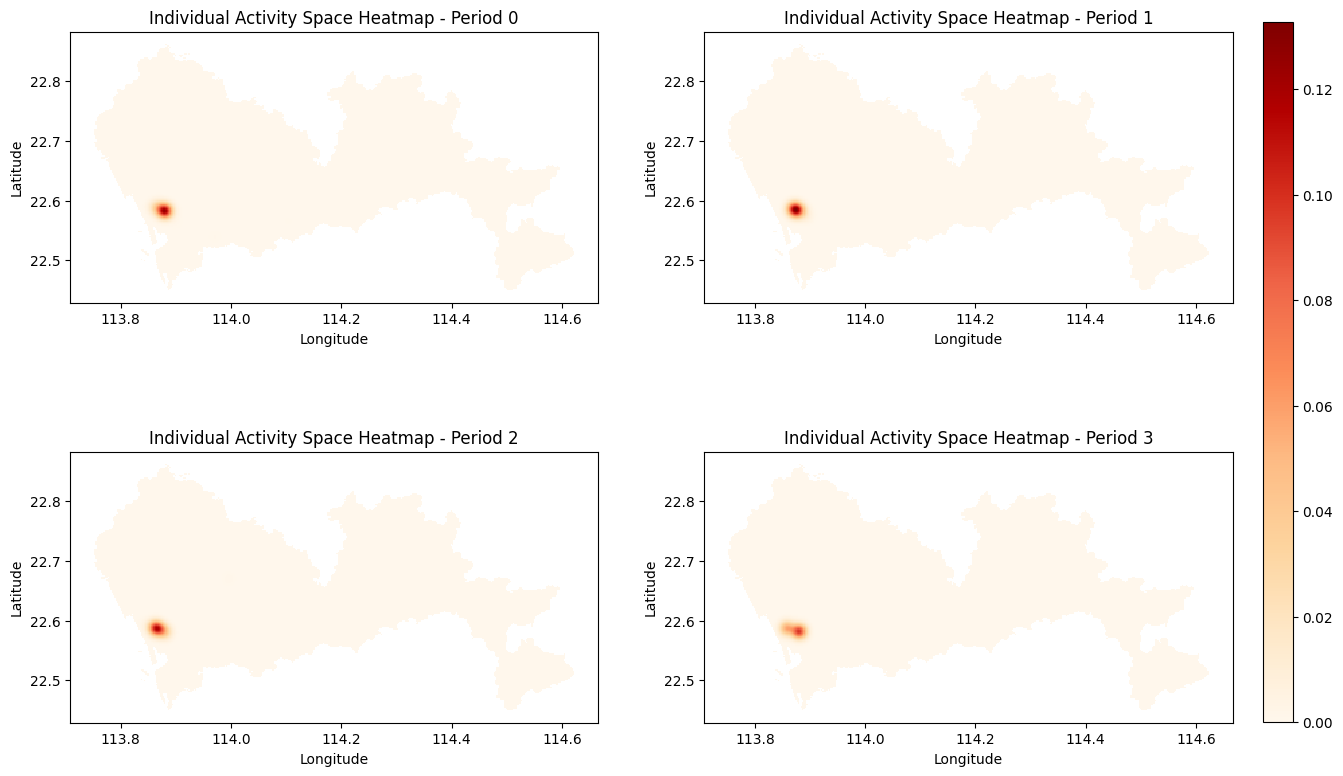

In [77]:
# 这里逐个时间切片生成热力图
# 创建2x2的子图布局
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

# 找到所有密度值的最大和最小值用于统一colorbar
vmin = min(np.min(result['density']) for result in density_results)
vmax = max(np.max(result['density']) for result in density_results)

# 创建一个颜色映射
cmap = plt.get_cmap('OrRd')

# 遍历每个时间段绘制热力图
for idx, result in enumerate(density_results):
    ss_grid_data['density'] = result['density']
    
    # 在对应的子图位置绘制
    plot = ss_grid_data.plot(column='density', ax=axes[idx],
                             cmap=cmap, vmin=vmin, vmax=vmax,
                             legend=False)
    axes[idx].set_title(f"Individual Activity Space Heatmap - Period {result['period']}")
    axes[idx].set_xlabel("Longitude")
    axes[idx].set_ylabel("Latitude")

# 添加共用的colorbar
# 获取最后一个图的颜色数据
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])  # 必须设置一个空数组来启动colorbar的构建

# 添加colorbar
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
plt.colorbar(sm, cax=cax)

# 调整布局，给colorbar留出空间
plt.subplots_adjust(right=0.9)  # This ensures there's enough room for the colorbar

# plt.tight_layout()
plt.show()

美化

In [12]:
# 学术资源加速
import subprocess

result = subprocess.run('bash -c "source /etc/network_turbo && env | grep proxy"', shell=True, capture_output=True, text=True)
output = result.stdout
for line in output.splitlines():
    if '=' in line:
        var, value = line.split('=', 1)
        os.environ[var] = value

In [13]:
def plot_activity_space_heatmap(density_results, ss_grid_data, threshold_rate=0.1, scale_bar_length=5000):
    """
    绘制活动空间热力图
    
    参数:
    density_results: 包含每个时间段密度结果的列表
    ss_grid_data: GeoDataFrame,包含网格数据
    threshold_rate: float,密度阈值比例,默认0.2
    scale_bar_length: float,比例尺长度,默认5000
    """
    # 创建2x2的子图布局
    fig, axes = plt.subplots(2, 2, figsize=(15, 8))
    axes = axes.flatten()

    # 找到所有密度值的最大和最小值用于统一colorbar
    vmin = min(np.min(result['density']) for result in density_results)
    vmax = max(np.max(result['density']) for result in density_results)

    # 转化为3857投影
    ss_grid_data_plot = ss_grid_data.copy().to_crs(epsg=3857)

    # 设置底图来源
    basemap_source = ctx.providers.CartoDB.Voyager
    
    # 创建一个颜色映射
    cmap = plt.get_cmap('magma')

    # 遍历每个时间段绘制热力图
    for idx, result in enumerate(density_results):
        ss_grid_data_plot['density'] = result['density']
        
        # 在对应的子图位置绘制
        ax = axes[idx]

        # 先绘制一个空的ss_grid_data_plot来确定底图范围
        ss_grid_data_plot.plot(ax=ax, alpha=0)
        ctx.add_basemap(ax, source=basemap_source, attribution=False)
        # ctx.add_basemap(ax, attribution=False)

        ax.set_axis_off()
        # 设置一个很小的阈值,低于该值的密度将被设为NaN从而不显示
        density_threshold = result['density'].max() * threshold_rate
        ss_grid_data_plot.loc[ss_grid_data_plot['density'] < density_threshold, 'density'] = np.nan
        
        plot = ss_grid_data_plot.plot(column='density', ax=ax,
                                 cmap=cmap, vmin=vmin, vmax=vmax,
                                 legend=False)
        if sz_poly is not None:
            sz_poly.to_crs(epsg=3857).plot(ax=ax, edgecolor='dimgray', facecolor='none', linestyle='--', linewidth=1)
        
        # 添加比例尺
        transform = ax.transData
        scale_bar = AnchoredSizeBar(transform, scale_bar_length, f'{scale_bar_length / 1000} km', loc='lower left', frameon=False, size_vertical=1, 
                                    fontproperties=FontProperties(size=8))
        ax.add_artist(scale_bar)

        # 添加指北针
        img = mpimg.imread('supporting_files/north_arrow.png')  # 读取指北针图片
        imagebox = OffsetImage(img, zoom=0.1)  # 设置指北针的大小，可以通过调整 zoom 来修改大小
        ab = AnnotationBbox(imagebox, (0.95, 0.9), xycoords='axes fraction', boxcoords="axes fraction", frameon=False, pad=0)  # 定义图片位置
        ax.add_artist(ab)  # 将指北针添加到当前子图
            
        ax.set_title(f"Individual Activity Space Heatmap - Period {result['period']}")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

    # 添加共用的colorbar
    # 获取最后一个图的颜色数据
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
    sm.set_array([])  # 必须设置一个空数组来启动colorbar的构建

    # 添加colorbar
    cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
    plt.colorbar(sm, cax=cax)

    # 调整布局，给colorbar留出空间
    plt.subplots_adjust(right=0.9)  # This ensures there's enough room for the colorbar

    plt.show()
    
    return fig, axes

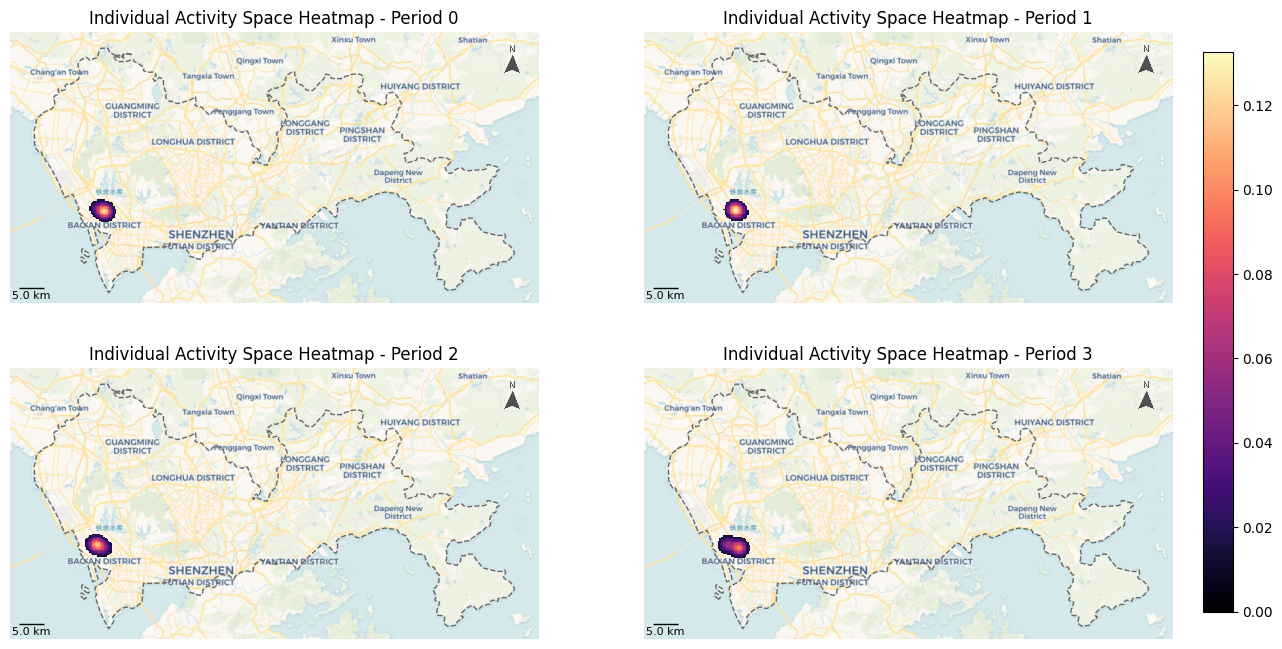

(<Figure size 1500x800 with 5 Axes>,
 array([<Axes: title={'center': 'Individual Activity Space Heatmap - Period 0'}, xlabel='Longitude', ylabel='Latitude'>,
        <Axes: title={'center': 'Individual Activity Space Heatmap - Period 1'}, xlabel='Longitude', ylabel='Latitude'>,
        <Axes: title={'center': 'Individual Activity Space Heatmap - Period 2'}, xlabel='Longitude', ylabel='Latitude'>,
        <Axes: title={'center': 'Individual Activity Space Heatmap - Period 3'}, xlabel='Longitude', ylabel='Latitude'>],
       dtype=object))

In [74]:
# 调用函数绘制热力图
plot_activity_space_heatmap(density_results, ss_grid_data)

**创建一个gif动图**
* 使用滑动时间窗口展示活动空间的动态变化过程

In [26]:
# 遍历时间切片，计算并保存每个切片下的核密度结果及活动空间特征
month_density_results = []
temporal_bandwidth = 4

# 改成每4周(t)计算一次核密度
min_t = int(gdf_sample['t'].min())
max_t = int(gdf_sample['t'].max())
time_slices = np.arange(min_t, max_t + 1, temporal_bandwidth)

for t_eval in time_slices:
    # 筛选当前4周时间窗口的数据点
    mask = (gdf_sample['t'] * temporal_bandwidth >= t_eval) & (gdf_sample['t'] * temporal_bandwidth < t_eval + temporal_bandwidth)
    current_data = data_scaled[mask]
    current_weights = weights[mask] if weights is not None else None

    if current_weights is None or current_weights.size == 0:
        density = np.array([])
    else:
        # 使用当前时间窗口的数据重新拟合KDE
        kde_t.fit(current_data, sample_weight=current_weights)

        # 计算当前时间切片的核密度
        log_density = kde_t.score_samples(eval_points)
        density = np.exp(log_density)

    # 将当前时期的密度结果添加到列表中
    month_density_results.append({
         'period': t_eval,
         'density': density
    })

In [75]:
# 滑动窗口版本

# 滑动窗口参数设置
window_size = 4  # 窗口大小（例如：每4个时间点为一个窗口）
step_size = 1    # 步长（每次滑动1个时间点）

# 计算时间切片
min_t = int(gdf_sample['t'].min())
max_t = int(gdf_sample['t'].max())
time_slices = np.arange(min_t, max_t - window_size + 1, step_size)

# 存储每个时间窗口的核密度结果
month_density_results = []

for t_eval in time_slices:
    # 筛选当前滑动窗口的数据点
    mask = (gdf_sample['t'] >= t_eval) & (gdf_sample['t'] < t_eval + window_size)
    current_data = data_scaled[mask]
    current_weights = weights[mask] if weights is not None else None

    if current_weights is None or current_weights.size == 0:
        density = np.array([])  # 如果没有有效的权重数据，设定密度为一个空数组
    else:
        # 使用当前时间窗口的数据重新拟合KDE
        kde_t.fit(current_data, sample_weight=current_weights)

        # 计算当前时间窗口的核密度
        log_density = kde_t.score_samples(eval_points)
        density = np.exp(log_density)

    # 将当前时期的密度结果添加到列表中
    month_density_results.append({
        'period': t_eval,
        'density': density
    })

/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/sklearn/neighbors/_kde.py:271: RuntimeWarning: divide by zero encountered in log
  log_density = self.tree_.kernel_density(
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/sklearn/neighbors/_kde.py:271: RuntimeWarning: divide by zero encountered in log
  log_density = self.tree_.kernel_density(
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/sklearn/neighbors/_kde.py:271: RuntimeWarning: divide by zero encountered in log
  log_density = self.tree_.kernel_density(
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/sklearn/neighbors/_kde.py:271: RuntimeWarning: divide by zero encountered in log
  log_density = self.tree_.kernel_density(


In [76]:
len(month_density_results)

75

In [20]:
def plot_activity_space_heatmap_gif(density_results, ss_grid_data, threshold_rate=0.2):
    """
    绘制活动空间热力图并生成一个GIF动画
    
    参数:
    density_results: 包含每个时间段密度结果的列表
    ss_grid_data: GeoDataFrame,包含网格数据
    threshold_rate: float,密度阈值比例,默认0.2
    output_gif: str, 保存GIF文件的路径
    """
    fig, ax = plt.subplots(figsize=(15, 8))

    # 找到所有密度值的最大和最小值用于统一colorbar
    # 过滤掉空数组的结果
    valid_density_values = [result['density'] for result in density_results if result['density'].size > 0]
    
    # 如果valid_density_values为空，表示没有有效的密度数据
    if valid_density_values:
        vmin = min(np.min(density) for density in valid_density_values)
        vmax = max(np.max(density) for density in valid_density_values)
    else:
        vmin = vmax = 0  # 默认设置为0

    # 转化为3857投影
    ss_grid_data_plot = ss_grid_data.copy().to_crs(epsg=3857)

    # 设置底图来源
    basemap_source = ctx.providers.CartoDB.Voyager
    # 创建一个颜色映射
    cmap = plt.get_cmap('magma')

    # 清除之前的绘制
    ax.clear()

    # 创建一个函数来更新动画帧
    def animate(i):
        ax.clear()  # 清除之前的绘制
        
        # 先绘制一个空的ss_grid_data_plot来确定底图范围
        ss_grid_data_plot.plot(ax=ax, alpha=0)

        # 获取当前时间段的密度数据
        result = density_results[i]

        if result['density'].size == 0:
            return []

        ss_grid_data_plot['density'] = result['density']

        # 设置一个很小的阈值,低于该值的密度将被设为NaN从而不显示
        density_threshold = result['density'].max() * threshold_rate
        ss_grid_data_plot.loc[ss_grid_data_plot['density'] < density_threshold, 'density'] = np.nan

        # 绘制密度图
        ss_grid_data_plot.plot(column='density', ax=ax,
                               cmap=cmap, vmin=vmin, vmax=vmax,
                               legend=False)

        ax.set_title(f"Individual Activity Space Heatmap - Period {result['period']}")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.set_axis_off()

        # 设置底图
        ctx.add_basemap(ax, source=basemap_source, attribution=False)

        return []

    # 创建动画
    ani = animation.FuncAnimation(fig, animate, frames=len(density_results), interval=1000, repeat=True)
    
    return ani
    
    # plt.close(fig)  # 防止内存泄漏

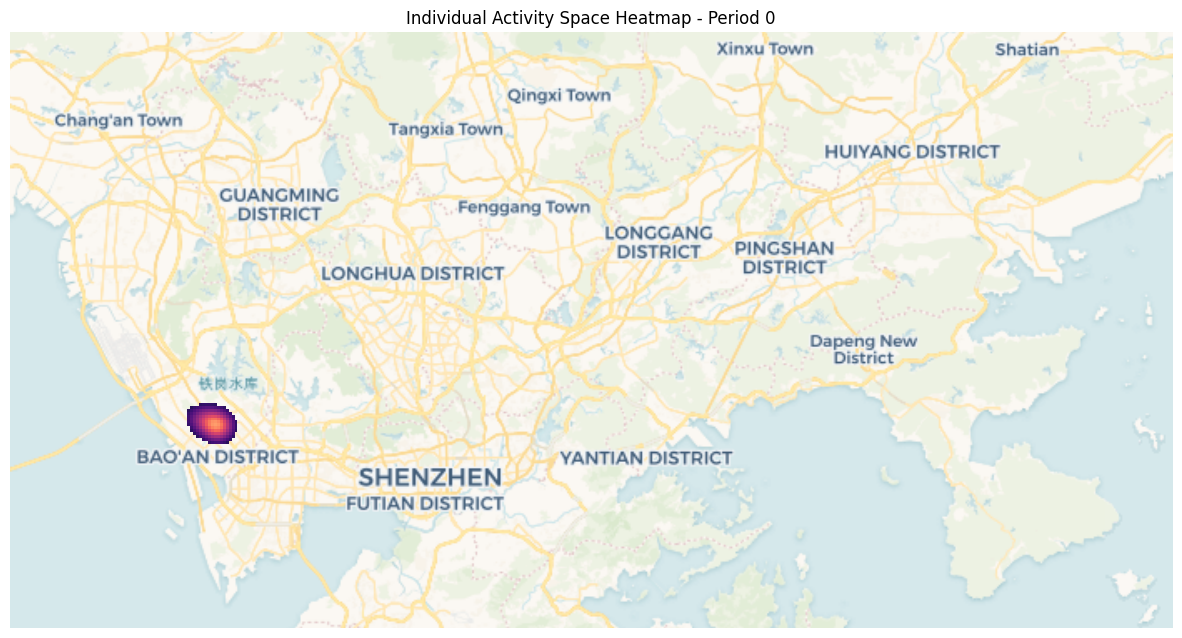

In [77]:
# 调用函数生成GIF
ani = plot_activity_space_heatmap_gif(month_density_results, ss_grid_data)

In [78]:
output_path = "results/activity_area_heatmap_mode3.gif"
writer = animation.PillowWriter(fps=4,
                                metadata=dict(artist='Me'),
                                bitrate=1800)
ani.save(output_path, writer=writer)
HTML(f'<img src={output_path}>')

<Figure size 640x480 with 0 Axes>